# Inferência Causal — IPTW / AIPW
**Pergunta central do Paper 1:**
*"Qual o efeito causal da documentação clínica precoce (evolução médica ≤ 4h da admissão)
sobre o retorno não programado em 30 dias em gestantes de alto risco?"*

Método: emulação de target trial com estimadores duplamente robustos (IPTW + AIPW)
Exposição (T): `IND_CONDUTA_PRECOCE` — presença de evolução médica nas primeiras 4h
Outcome (Y): `y_retorno_30d`
Confundidores (X): idade, CID, setor, IG, paridade, escore triagem, complexidade

In [1]:
from __future__ import annotations
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

warnings.filterwarnings("ignore")

ROOT    = Path("..").resolve()
OUT_DIR = ROOT / "out" / f"causal_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
PLOT_DIR = OUT_DIR / "plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Carga dos Dados

In [2]:
import duckdb as _ddb
_DUCKDB        = ROOT / "data" / "gestante.duckdb"
_PARQUET_ENRIQ = ROOT / "data" / "gestante_quadro_clinico_enriquecido.parquet"

_tabs = _ddb.connect(str(_DUCKDB)).execute("SHOW TABLES").df()["name"].tolist()
if "gestante_enriquecido" in _tabs:
    _con = _ddb.connect(str(_DUCKDB))
    df = _con.execute("SELECT * FROM gestante_enriquecido").df()
    _con.close()
    df.columns = df.columns.str.lower()
    print(f"DuckDB gestante_enriquecido carregado: {len(df):,} registros")
elif _PARQUET_ENRIQ.exists():
    df = pd.read_parquet(_PARQUET_ENRIQ)
    df.columns = df.columns.str.lower()
    print(f"Parquet enriquecido carregado: {len(df):,} registros")
else:
    # fallback: processa do zero
    import sys; sys.path.insert(0, str(ROOT / "src"))
    from build_obstetric_features import enrich_obstetric
    df = pd.read_parquet(ROOT/"data"/"gestante_quadro_clinico.parquet")
    df.columns = df.columns.str.lower()
    df = df[df["is_recem_nascido"] == 0].copy()
    LLM_PARQUET = ROOT / "out" / "llm_extracted_20k.parquet"
    df = enrich_obstetric(df, llm_parquet=str(_DUCKDB))
    df = df[(df.flag_neonatal == 0)].copy()
    print(f"Processado do zero: {len(df):,} registros")

for c in ["dt_atendimento","dt_alta","dh_primeira_evolucao"]:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors="coerce")

# ── Exposição: conduta documentada precoce ─────────────────────────────────
# Definição: evolução médica registrada nas primeiras 4 horas do atendimento
df["horas_ate_1a_evolucao"] = (
    (df["dh_primeira_evolucao"] - df["dt_atendimento"])
    .dt.total_seconds() / 3600
)
df["T"] = (
    (df["qtd_evolucoes_documentadas"] > 0) &
    (df["horas_ate_1a_evolucao"] <= 4) &
    (df["horas_ate_1a_evolucao"] >= 0)
).astype(int)

for n in df.columns:
    print('nome', n)
# ── Outcome ────────────────────────────────────────────────────────────────
df["Y"] = (df["sn_retorno_30d"].fillna("N") == "S").astype(int)

# ── Features obstétricas ───────────────────────────────────────────────────
df["idade_anos"]   = pd.to_numeric(df.get("idade_anos"),   errors="coerce")
df["semanas_gest"] = pd.to_numeric(df["ig_obs"].fillna(df["semanas_gestacao"]), errors="coerce")

def seg_cid(c):
    if pd.isna(c): return "SEM_CID"
    c = str(c).upper()
    if c[:3] in [f"O{i:02d}" for i in range(10,17)]: return "HIPERTENSIVOS"
    if c[:3]=="O24": return "DIABETES_GEST"
    if c[:3] in ["O60","O42","O47"]: return "PARTO_PREMATURO"
    if c[0]=="O": return "OUTROS_OBST"
    return "OUTROS"

df["segmento_cid"] = df["cd_cid"].apply(seg_cid)

# Mantém apenas internações (T faz sentido para internados)
df = df[df["tp_atendimento"].isin(["I","U"])].copy()

# Remove casos sem data de evolução e sem possibilidade de calcular exposição
# (ambulatório sem internação não tem evolução médica rotineira)
df_analise = df[
    df["dt_atendimento"].notna() &
    df["idade_anos"].notna()
].copy()

print(f"Coorte de análise: {len(df_analise):,}")
print(f"Expostos (T=1):    {df_analise['T'].sum():,} ({df_analise['T'].mean()*100:.1f}%)")
print(f"Não expostos (T=0):{(1-df_analise['T']).sum():,}")
print(f"Outcome Y=1:       {df_analise['Y'].sum():,} ({df_analise['Y'].mean()*100:.1f}%)")

## 2. Análise Descritiva — Balanceamento Pré-Ponderação

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

CONFUNDIDORES = [
    "idade_anos","segmento_cid","tp_atendimento",
    "semanas_gest","qtd_diagnosticos","qtd_pedidos_lab",
    "vl_escore_triagem","duracao_horas_aprox",
    # Obstétricas enriquecidas — controlam perfil gestacional
    "tipo_gestacao",        # GUTT/GURT/GUPT/etc.
    "risco_gestacao",       # 1 = alto risco gestacional
    "gestacao_gemelar",
    "gestacao_pretermo",
    "G_obs",                # número de gestações
    "grande_multipara_v2",  # G>=5
    "tem_aborto_v2",
    "perfil_historico",     # PRIMIGESTA/MULTIPARA_COM_PERDA/ABORTO_RECORRENTE/etc.
    "perda_previa",         # A≥1 ou G>1 e N=0
    "aborto_recorrente",    # A≥2
]
CONFUNDIDORES = [c for c in CONFUNDIDORES if c in df_analise.columns]

# SMD antes do ajuste
def smd(df, col, treatment_col="T"):
    """Standardized Mean Difference."""
    g1 = pd.to_numeric(df[df[treatment_col]==1][col], errors="coerce").dropna()
    g0 = pd.to_numeric(df[df[treatment_col]==0][col], errors="coerce").dropna()
    if len(g1)==0 or len(g0)==0: return np.nan
    pooled_sd = np.sqrt((g1.std()**2 + g0.std()**2) / 2)
    if pooled_sd == 0: return 0.0
    return abs(g1.mean() - g0.mean()) / pooled_sd

smd_pre = {c: smd(df_analise, c) for c in CONFUNDIDORES
           if pd.api.types.is_numeric_dtype(df_analise[c])}
smd_df  = pd.DataFrame(list(smd_pre.items()), columns=["variavel","smd_pre"]) \
            .dropna().sort_values("smd_pre", ascending=False)
print("\nSMD pré-ponderação (>0.1 = desequilíbrio relevante):")
print(smd_df.to_string(index=False))

## 3. Propensity Score — Modelo de Probabilidade da Exposição

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier

num_cols = [c for c in CONFUNDIDORES if pd.api.types.is_numeric_dtype(df_analise[c])]
cat_cols = [c for c in CONFUNDIDORES if c not in num_cols]

pre_ps = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
], remainder="drop")

X_ps = pre_ps.fit_transform(df_analise[CONFUNDIDORES])
T    = df_analise["T"].values
Y    = df_analise["Y"].values

# Propensity score com Gradient Boosting (mais estável que LogReg puro)
ps_model = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.05,
    random_state=42
)
ps_model.fit(X_ps, T)
ps = ps_model.predict_proba(X_ps)[:,1]
df_analise["ps"] = ps

print(f"\nPropensity Score — distribuição:")
print(f"  Expostos (T=1):  média={ps[T==1].mean():.3f}  std={ps[T==1].std():.3f}")
print(f"  Controles (T=0): média={ps[T==0].mean():.3f}  std={ps[T==0].std():.3f}")

## 4. Overlap — Distribuição do PS

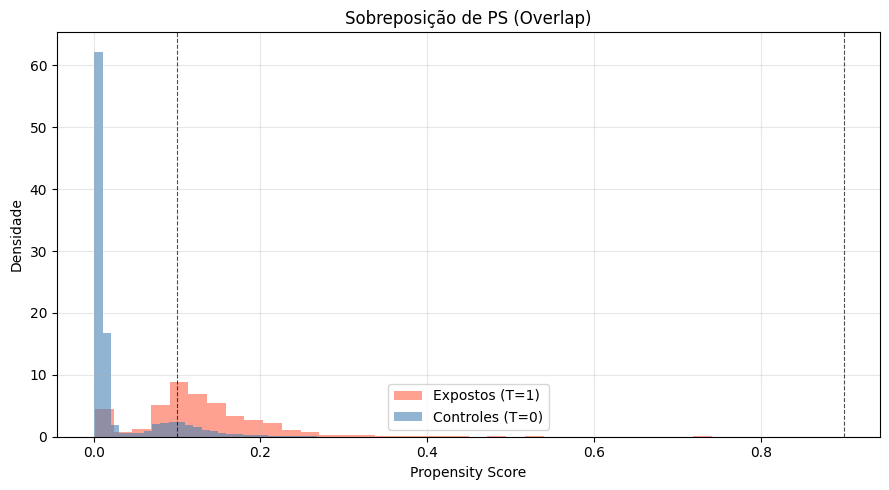

In [5]:
fig, ax = plt.subplots(figsize=(9,5))
ax.hist(ps[T==1], bins=40, alpha=0.6, color="tomato",   label="Expostos (T=1)",    density=True)
ax.hist(ps[T==0], bins=40, alpha=0.6, color="steelblue",label="Controles (T=0)",   density=True)
ax.axvline(0.1, color="black", ls="--", lw=0.8, alpha=0.7)
ax.axvline(0.9, color="black", ls="--", lw=0.8, alpha=0.7)
ax.set_xlabel("Propensity Score"); ax.set_ylabel("Densidade")
ax.set_title("Sobreposição de PS (Overlap)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR/"01_overlap_ps.png", dpi=150); plt.show(); plt.close()

# Trimming: remove PS extremos (< 0.05 ou > 0.95)
mask_overlap = (ps >= 0.05) & (ps <= 0.95)
n_trimmed = (~mask_overlap).sum()
print(f"\nTrimming: {n_trimmed} obs. removidas (PS < 0.05 ou > 0.95)")

df_trim = df_analise[mask_overlap].copy()
ps_trim = ps[mask_overlap]
T_trim  = T[mask_overlap]
Y_trim  = Y[mask_overlap]

## 5. IPTW — Inverse Probability of Treatment Weighting

In [6]:
# Pesos IPTW (ATE)
eps = 1e-6
w_iptw = np.where(T_trim==1,
                  1 / (ps_trim + eps),
                  1 / (1 - ps_trim + eps))

# Estabilização dos pesos (evita valores extremos)
p_t   = T_trim.mean()
w_iptw = np.where(T_trim==1,
                  p_t / (ps_trim + eps),
                  (1-p_t) / (1-ps_trim + eps))

# Clipping de pesos (percentil 99)
w_clip = np.clip(w_iptw, 0, np.percentile(w_iptw, 99))
df_trim["w_iptw"] = w_clip

print(f"\nIPTW — pesos:")
print(f"  Média:    {w_clip.mean():.3f}")
print(f"  Mediana:  {np.median(w_clip):.3f}")
print(f"  Max:      {w_clip.max():.3f}")

# Estimativa IPTW do ATE
Y1_iptw = (Y_trim[T_trim==1] * w_clip[T_trim==1]).sum() / w_clip[T_trim==1].sum()
Y0_iptw = (Y_trim[T_trim==0] * w_clip[T_trim==0]).sum() / w_clip[T_trim==0].sum()
ate_iptw = Y1_iptw - Y0_iptw

print(f"\nIPTW — Estimativa ATE (Retorno 30d):")
print(f"  E[Y(1)] = {Y1_iptw:.4f}  ({Y1_iptw*100:.2f}%)")
print(f"  E[Y(0)] = {Y0_iptw:.4f}  ({Y0_iptw*100:.2f}%)")
print(f"  ATE     = {ate_iptw:+.4f}  ({ate_iptw*100:+.2f} pp)")

## 6. AIPW — Augmented IPW (Duplamente Robusto)

In [7]:
# Modelo de outcome (E[Y|X,T])
from sklearn.ensemble import GradientBoostingClassifier as GBC

X_out = np.hstack([X_ps[mask_overlap], T_trim.reshape(-1,1)])
out_model = GBC(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
out_model.fit(X_out, Y_trim)

# Predições contrafactuais
X1 = np.hstack([X_ps[mask_overlap], np.ones((mask_overlap.sum(),1))])
X0 = np.hstack([X_ps[mask_overlap], np.zeros((mask_overlap.sum(),1))])
mu1 = out_model.predict_proba(X1)[:,1]
mu0 = out_model.predict_proba(X0)[:,1]

# Estimador AIPW
score_1 = mu1 + (T_trim * (Y_trim - mu1)) / (ps_trim[mask_overlap[mask_overlap]] + eps \
          if len(ps_trim) != mask_overlap.sum() else ps_trim + eps)
score_0 = mu0 + ((1-T_trim) * (Y_trim - mu0)) / (1 - ps_trim + eps)

# Correção de indexação
score_1 = mu1 + T_trim * (Y_trim - mu1) / (ps_trim + eps)
score_0 = mu0 + (1-T_trim) * (Y_trim - mu0) / (1 - ps_trim + eps)
ate_aipw = (score_1 - score_0).mean()

# Bootstrap IC95% para AIPW
rng = np.random.default_rng(42)
boot_ates = []
for _ in range(500):
    idx = rng.integers(0, len(Y_trim), len(Y_trim))
    boot_ates.append((score_1[idx] - score_0[idx]).mean())

ic_lo, ic_hi = np.percentile(boot_ates, [2.5, 97.5])
se = np.std(boot_ates)

print(f"\nAIPW — Estimativa ATE (duplamente robusto):")
print(f"  ATE     = {ate_aipw:+.4f}  ({ate_aipw*100:+.2f} pp)")
print(f"  IC95%   = [{ic_lo:+.4f}, {ic_hi:+.4f}]")
from scipy.stats import norm as _norm_inline
pval_inline = 2 * (1 - _norm_inline.cdf(abs(ate_aipw / se)))
print(f"  SE      = {se:.4f}")
print(f"  p-valor ≈ {pval_inline:.4f}")

## 7. SMD Pós-Ponderação (Balanceamento)

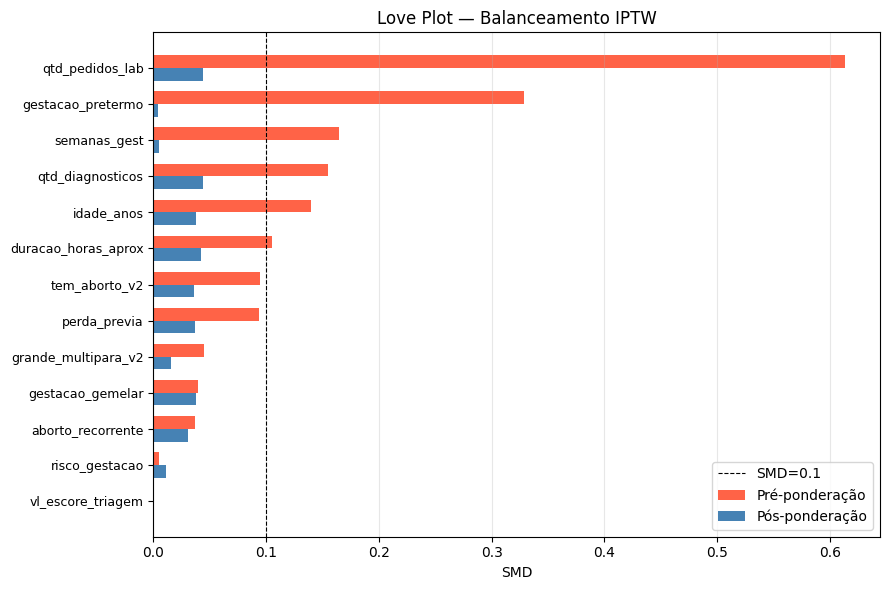

In [8]:
smd_post = {}
for col in smd_pre.keys():
    try:
        g1 = df_trim[df_trim["T"]==1][col] * df_trim[df_trim["T"]==1]["w_iptw"]
        g0 = df_trim[df_trim["T"]==0][col] * df_trim[df_trim["T"]==0]["w_iptw"]
        g1n = pd.to_numeric(df_trim[df_trim["T"]==1][col], errors="coerce").dropna()
        g0n = pd.to_numeric(df_trim[df_trim["T"]==0][col], errors="coerce").dropna()
        pooled = np.sqrt((g1n.std()**2 + g0n.std()**2)/2)
        if pooled==0: smd_post[col]=0.0; continue
        w1 = df_trim[df_trim["T"]==1]["w_iptw"].values
        w0 = df_trim[df_trim["T"]==0]["w_iptw"].values
        m1 = np.average(g1n, weights=w1[:len(g1n)])
        m0 = np.average(g0n, weights=w0[:len(g0n)])
        smd_post[col] = abs(m1-m0)/pooled
    except Exception:
        smd_post[col] = np.nan

smd_df["smd_pos"] = smd_df["variavel"].map(smd_post)
print("\nBalanceamento (SMD < 0.1 = balanceado):")
print(smd_df.to_string(index=False))
smd_df.to_csv(OUT_DIR/"smd_balanceamento.csv", index=False)

# Love plot
fig, ax = plt.subplots(figsize=(9,6))
y_pos = range(len(smd_df))
ax.barh(y_pos, smd_df["smd_pre"][::-1],  height=0.35, label="Pré-ponderação",
        color="tomato",   align="edge")
ax.barh([y-0.35 for y in y_pos], smd_df["smd_pos"][::-1], height=0.35,
        label="Pós-ponderação", color="steelblue", align="edge")
ax.axvline(0.1, color="black", ls="--", lw=0.8, label="SMD=0.1")
ax.set_yticks(list(y_pos))
ax.set_yticklabels(smd_df["variavel"][::-1], fontsize=9)
ax.set_xlabel("SMD"); ax.set_title("Love Plot — Balanceamento IPTW")
ax.legend(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR/"02_love_plot.png", dpi=150); plt.show(); plt.close()

## 8. Análise de Heterogeneidade — CATE por Subgrupo

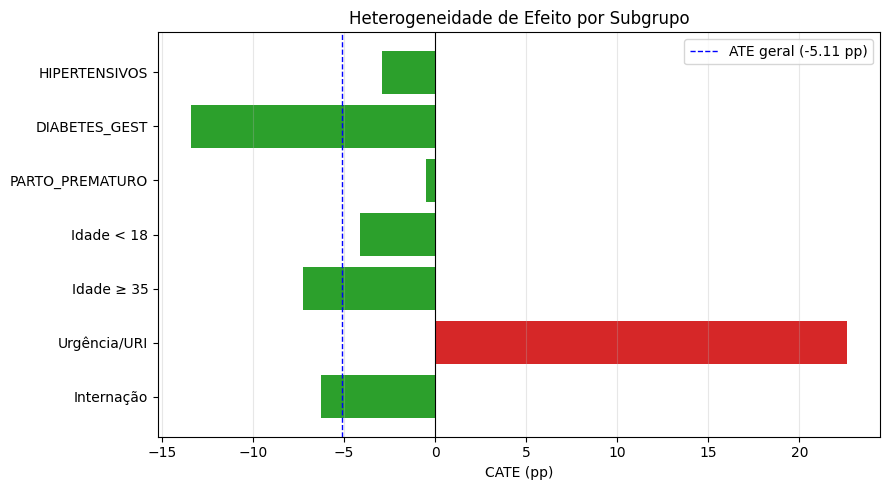

In [9]:
subgrupos = {
    "HIPERTENSIVOS": df_trim["segmento_cid"]=="HIPERTENSIVOS",
    "DIABETES_GEST": df_trim["segmento_cid"]=="DIABETES_GEST",
    "PARTO_PREMATURO": df_trim["segmento_cid"]=="PARTO_PREMATURO",
    "Idade < 18":   df_trim["idade_anos"] < 18,
    "Idade ≥ 35":   df_trim["idade_anos"] >= 35,
    "Urgência/URI": df_trim["tp_atendimento"]=="U",
    "Internação":   df_trim["tp_atendimento"]=="I",
}

rows_het = []
for nome_sub, mask_sub in subgrupos.items():
    sub = df_trim[mask_sub]
    if len(sub) < 30: continue
    s1_sub = score_1[mask_sub.values]
    s0_sub = score_0[mask_sub.values]
    ate_sub = (s1_sub - s0_sub).mean()
    n_sub   = mask_sub.sum()
    prev_sub = sub["Y"].mean()
    rows_het.append({"subgrupo":nome_sub, "n":n_sub,
                     "prev_retorno_30d": round(prev_sub*100,1),
                     "CATE_pp": round(ate_sub*100,2)})

het_df = pd.DataFrame(rows_het)
print("\nHeterogeneidade de efeito (CATE por subgrupo):")
print(het_df.to_string(index=False))
het_df.to_csv(OUT_DIR/"cate_subgrupos.csv", index=False)

fig, ax = plt.subplots(figsize=(9,5))
cores_h = ["#d62728" if v>0 else "#2ca02c" for v in het_df["CATE_pp"]]
ax.barh(het_df["subgrupo"][::-1], het_df["CATE_pp"][::-1], color=cores_h[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.axvline(ate_aipw*100, color="blue", ls="--", lw=1,
           label=f"ATE geral ({ate_aipw*100:+.2f} pp)")
ax.set_xlabel("CATE (pp)"); ax.set_title("Heterogeneidade de Efeito por Subgrupo")
ax.legend(); ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR/"03_cate_subgrupos.png", dpi=150); plt.show(); plt.close()

## 9. Efeito Causal da Má Documentação na Duração da Internação

**Pergunta:** Pacientes com documentação clínica deficiente ficam mais horas internadas?

Exposição (T_doc): documentação DEFICIENTE = 0 evoluções durante toda a internação
Outcome (Y_horas): duracao_horas_aprox (tempo total de internação)
Método: AIPW com outcome contínuo

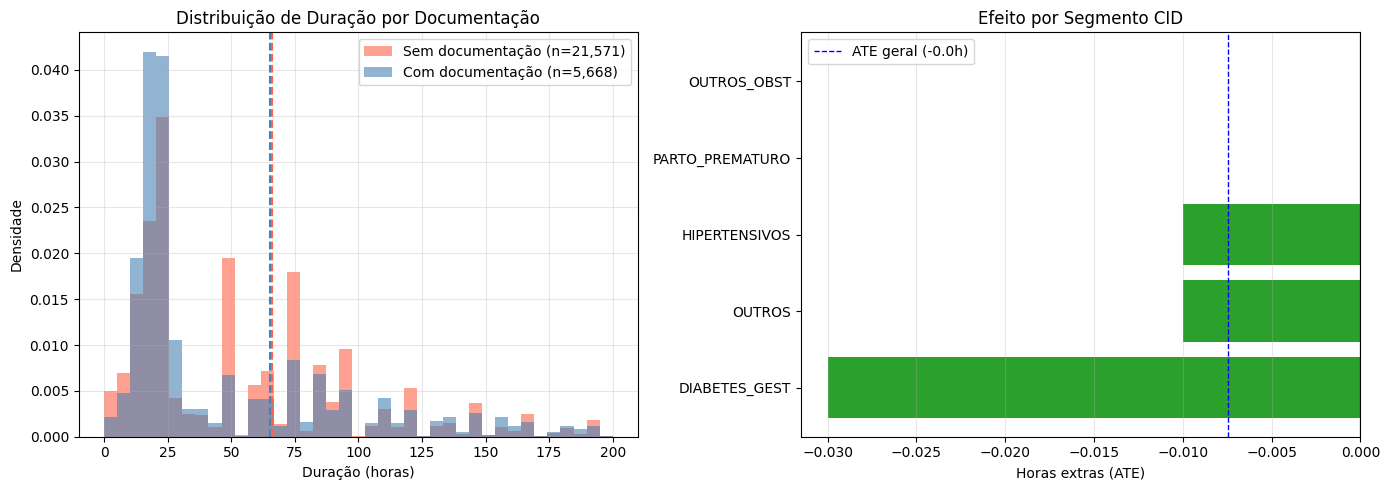

In [10]:
df_dur = df[
    df["tp_atendimento"].isin(["I","U"]) &
    df["duracao_horas_aprox"].notna() &
    df["duracao_horas_aprox"].between(1, 720) &  # 1h a 30 dias (remove outliers)
    df["dt_atendimento"].notna() &
    df["idade_anos"].notna()
].copy()

# Exposição: documentação deficiente (sem nenhuma evolução)
df_dur["T_doc"] = (df_dur["qtd_evolucoes_documentadas"].fillna(0) == 0).astype(int)
Y_dur = df_dur["duracao_horas_aprox"].values
T_doc = df_dur["T_doc"].values

print(f"Coorte duração: {len(df_dur):,}")
print(f"Sem documentação (T=1): {T_doc.sum():,} ({T_doc.mean()*100:.1f}%)")
print(f"Com documentação (T=0): {(1-T_doc).sum():,}")
print(f"\nDuração média — sem doc: {Y_dur[T_doc==1].mean():.1f}h  |  com doc: {Y_dur[T_doc==0].mean():.1f}h")
print(f"Diferença bruta (sem ajuste): {Y_dur[T_doc==1].mean() - Y_dur[T_doc==0].mean():+.1f}h")

# Propensity score para documentação deficiente
CONF_DUR = [c for c in CONFUNDIDORES if c in df_dur.columns]
pre_dur  = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]),
     [c for c in CONF_DUR if pd.api.types.is_numeric_dtype(df_dur[c])]),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
     [c for c in CONF_DUR if not pd.api.types.is_numeric_dtype(df_dur[c])]),
], remainder="drop")

X_dur = pre_dur.fit_transform(df_dur[CONF_DUR])
ps_doc = GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                     learning_rate=0.05, random_state=42)
ps_doc.fit(X_dur, T_doc)
ps_dur = ps_doc.predict_proba(X_dur)[:,1]

# Trimming
mask_dur = (ps_dur >= 0.05) & (ps_dur <= 0.95)
print(f"Trimming: {(~mask_dur).sum()} obs. removidas")

X_dur_t  = X_dur[mask_dur]
T_dur_t  = T_doc[mask_dur]
Y_dur_t  = Y_dur[mask_dur]
ps_dur_t = ps_dur[mask_dur]

# Modelo de outcome (duração ~ contínua)
from sklearn.ensemble import GradientBoostingRegressor
X_out_dur = np.hstack([X_dur_t, T_dur_t.reshape(-1,1)])
out_dur   = GradientBoostingRegressor(n_estimators=200, max_depth=3,
                                       learning_rate=0.05, random_state=42)
out_dur.fit(X_out_dur, Y_dur_t)

X1_dur = np.hstack([X_dur_t, np.ones((len(X_dur_t),1))])
X0_dur = np.hstack([X_dur_t, np.zeros((len(X_dur_t),1))])
mu1_dur = out_dur.predict(X1_dur)
mu0_dur = out_dur.predict(X0_dur)

eps = 1e-6
sc1_dur = mu1_dur + T_dur_t * (Y_dur_t - mu1_dur) / (ps_dur_t + eps)
sc0_dur = mu0_dur + (1-T_dur_t) * (Y_dur_t - mu0_dur) / (1 - ps_dur_t + eps)
ate_dur  = (sc1_dur - sc0_dur).mean()

# Bootstrap IC95%
rng2 = np.random.default_rng(42)
boot_dur = []
for _ in range(500):
    idx = rng2.integers(0, len(Y_dur_t), len(Y_dur_t))
    boot_dur.append((sc1_dur[idx] - sc0_dur[idx]).mean())
ic_lo_dur, ic_hi_dur = np.percentile(boot_dur, [2.5, 97.5])
se_dur = np.std(boot_dur)
pval_dur = 2 * (1 - _norm_inline.cdf(abs(ate_dur / se_dur)))

print(f"\n{'='*55}")
print(f"EFEITO CAUSAL — Má documentação → Duração internação")
print(f"{'='*55}")
print(f"  ATE  = {ate_dur:+.2f} horas")
print(f"  IC95% = [{ic_lo_dur:+.2f}, {ic_hi_dur:+.2f}] horas")
print(f"  SE   = {se_dur:.2f}")
print(f"  p    = {pval_dur:.4f}")
print(f"\n  Interpretação:")
if ate_dur > 0:
    print(f"  Pacientes SEM documentação ficam em média {ate_dur:.1f}h A MAIS")
    print(f"  internadas (IC95% {ic_lo_dur:.1f}h–{ic_hi_dur:.1f}h), p={pval_dur:.4f}")
else:
    print(f"  Sem efeito significativo na direção esperada")

# Distribuição por grupo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma duração por grupo
bins = np.linspace(0, 200, 40)
axes[0].hist(Y_dur_t[T_dur_t==1], bins=bins, alpha=0.6,
             color="tomato",    label=f"Sem documentação (n={T_dur_t.sum():,})",    density=True)
axes[0].hist(Y_dur_t[T_dur_t==0], bins=bins, alpha=0.6,
             color="steelblue", label=f"Com documentação (n={(1-T_dur_t).sum():,})", density=True)
axes[0].axvline(Y_dur_t[T_dur_t==1].mean(), color="tomato",    ls="--", lw=1.5)
axes[0].axvline(Y_dur_t[T_dur_t==0].mean(), color="steelblue", ls="--", lw=1.5)
axes[0].set_xlabel("Duração (horas)"); axes[0].set_ylabel("Densidade")
axes[0].set_title("Distribuição de Duração por Documentação")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Efeito por segmento CID
rows_dur_sub = []
for seg_nome in df_dur["segmento_cid"].value_counts().index[:6]:
    mask_s = (df_dur["segmento_cid"] == seg_nome).values[mask_dur]
    if mask_s.sum() < 20: continue
    ate_s = (sc1_dur[mask_s] - sc0_dur[mask_s]).mean()
    n_s   = mask_s.sum()
    rows_dur_sub.append({"segmento": seg_nome, "n": n_s, "ate_horas": round(ate_s, 2)})

dur_sub = pd.DataFrame(rows_dur_sub).sort_values("ate_horas", ascending=False)
cores_d = ["#d62728" if v>0 else "#2ca02c" for v in dur_sub["ate_horas"]]
axes[1].barh(dur_sub["segmento"][::-1], dur_sub["ate_horas"][::-1], color=cores_d[::-1])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].axvline(ate_dur, color="blue", ls="--", lw=1,
                label=f"ATE geral ({ate_dur:+.1f}h)")
axes[1].set_xlabel("Horas extras (ATE)"); axes[1].set_title("Efeito por Segmento CID")
axes[1].legend(); axes[1].grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR/"04_duracao_documentacao.png", dpi=150); plt.show(); plt.close()

dur_sub.to_csv(OUT_DIR/"causal_duracao_por_segmento.csv", index=False)

## 10. Resumo para o Paper

In [11]:
import json as _json
from scipy import stats as _stats

from scipy.stats import norm as _norm
z    = ate_aipw / se
pval = 2 * (1 - _norm.cdf(abs(z)))

resumo = {
    "exposicao":     "Documentação clínica precoce (evolução ≤ 4h da admissão)",
    "outcome":       "Retorno não programado em 30 dias",
    "metodo":        "AIPW (duplamente robusto) + IPTW",
    "n_analise":     int(mask_overlap.sum()),
    "n_expostos":    int(T_trim.sum()),
    "n_controles":   int((1-T_trim).sum()),
    "ate_iptw_pp":   round(ate_iptw*100, 2),
    "ate_aipw_pp":   round(ate_aipw*100, 2),
    "ic95_lo_pp":    round(ic_lo*100, 2),
    "ic95_hi_pp":    round(ic_hi*100, 2),
    "se":            round(se, 4),
    "p_valor":       round(pval, 4),
    "interpretacao": (
        f"A documentação clínica precoce esteve associada a uma diferença de "
        f"{ate_aipw*100:+.2f} pp (IC95% {ic_lo*100:+.2f} a {ic_hi*100:+.2f}) "
        f"na probabilidade de retorno em 30 dias (p={pval:.4f})."
    ),
}

print("\n" + "="*60)
print("RESUMO CAUSAL")
print("="*60)
for k,v in resumo.items():
    print(f"  {k:25s}: {v}")

(OUT_DIR/"resumo_causal.json").write_text(
    _json.dumps(resumo, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"\n✅ Inferência causal concluída — {OUT_DIR}")
print(f"   smd_balanceamento.csv | cate_subgrupos.csv | resumo_causal.json")